In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/uciml/breast-cancer-wisconsin-data/data.csv



# AdaBoost (Adaptive Boosting) – From Scratch and Scikit-learn

## 1. Introduction

AdaBoost (Adaptive Boosting) is an Ensemble Learning technique that combines multiple weak learners to create a strong learner.

It belongs to the Boosting family of ensemble methods. Unlike Bagging, where models are trained independently, Boosting trains models sequentially.

Each new weak learner focuses more on the observations that were incorrectly classified by the previous learner.

## 2. Dataset Description

**Dataset:** Breast Cancer Wisconsin Diagnostic Dataset

**Source:** Scikit-learn / UCI Machine Learning Repository

**Problem Type:** Binary Classification

**Target Variable:**
- 0 – Malignant
- 1 – Benign

The dataset contains numerical features extracted from digitized images of breast mass samples.

## 3. Working of AdaBoost

1. Initialize equal weights for all training samples.
2. Train a weak learner, usually a Decision Stump (Decision Tree with max_depth=1).
3. Calculate the weighted classification error.
4. Calculate the importance of the weak learner using Alpha.
5. Increase the weights of incorrectly classified samples.
6. Decrease the weights of correctly classified samples.
7. Normalize the sample weights.
8. Repeat the process for multiple iterations.
9. Combine all weak learners using weighted voting.

## 4. Important Mathematical Formulas

### A. Initial Sample Weights

For N training samples:

w(i) = 1/N

### B. Weighted Classification Error

Error = Sum of weights of misclassified samples

### C. Weak Learner Weight (Alpha)

Alpha = 1/2 × ln((1 - Error) / Error)

### D. Update Sample Weights

w(i) = w(i) × exp(-Alpha × y(i) × prediction(i))

Where:
- y(i) = Actual class label (-1 or +1)
- prediction(i) = Predicted class label (-1 or +1)
- Alpha = Importance of the weak learner

### E. Normalize Weights

w(i) = w(i) / Sum of all sample weights

## 5. Implementation Approaches

We will implement AdaBoost in two ways:

### Approach 1: From Scratch

- Initialize sample weights.
- Train Decision Stumps.
- Calculate weighted errors.
- Calculate Alpha values.
- Update sample weights.
- Make final predictions using weighted voting.

### Approach 2: Using Scikit-learn

Use:
- AdaBoostClassifier
- DecisionTreeClassifier
- Accuracy Score
- Confusion Matrix
- Classification Report

## 6. Model Evaluation

We will compare both implementations using:

- Accuracy
- Precision
- Recall
- F1-Score
- Confusion Matrix

## 7. Objective

Understand the internal working of AdaBoost by implementing its mathematical operations manually and comparing the results with Scikit-learn's implementation.


In [2]:
# Data manipulation
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset
from sklearn.datasets import load_breast_cancer

# Load dataset
data = load_breast_cancer(as_frame=True)

# Convert into DataFrame
df = data.frame

# Display first 5 rows
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [3]:
# Dataset shape
print("Shape:", df.shape)

# Dataset information
df.info()

# Statistical summary
display(df.describe())

# Missing values
print("Missing Values:", df.isnull().sum().sum())

# Target distribution
print("\nTarget Distribution:")
print(df['target'].value_counts())

# Target labels
print("\nTarget Names:", data.target_names)

Shape: (569, 31)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothnes

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


Missing Values: 0

Target Distribution:
target
1    357
0    212
Name: count, dtype: int64

Target Names: ['malignant' 'benign']


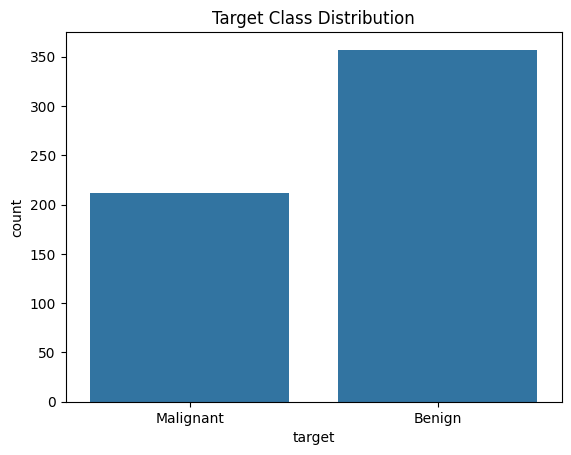

In [4]:
sns.countplot(data=df, x='target')

plt.title("Target Class Distribution")
plt.xticks([0, 1], ['Malignant', 'Benign'])
plt.show()

In [5]:
# Independent variables
X = df.drop('target', axis=1)

# Original target
y = df['target']

# Convert target labels for scratch implementation
y_scratch = y.map({0: -1, 1: 1})

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nUnique labels:", np.unique(y_scratch))

Features Shape: (569, 30)
Target Shape: (569,)

Unique labels: [-1  1]


In [6]:
from sklearn.model_selection import train_test_split

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_scratch,
    test_size=0.2,
    random_state=42,
    stratify=y_scratch
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (455, 30)
X_test: (114, 30)
y_train: (455,)
y_test: (114,)


In [7]:
# Number of training samples
n_samples = len(X_train)

# Initialize equal weights
sample_weights = np.ones(n_samples) / n_samples

# Display first 10 sample weights
print("First 10 Sample Weights:")
print(sample_weights[:10])

# Check total weight
print("\nTotal Weight:", sample_weights.sum())

# Check individual weight
print("Individual Weight:", sample_weights[0])

First 10 Sample Weights:
[0.0021978 0.0021978 0.0021978 0.0021978 0.0021978 0.0021978 0.0021978
 0.0021978 0.0021978 0.0021978]

Total Weight: 0.9999999999999998
Individual Weight: 0.002197802197802198


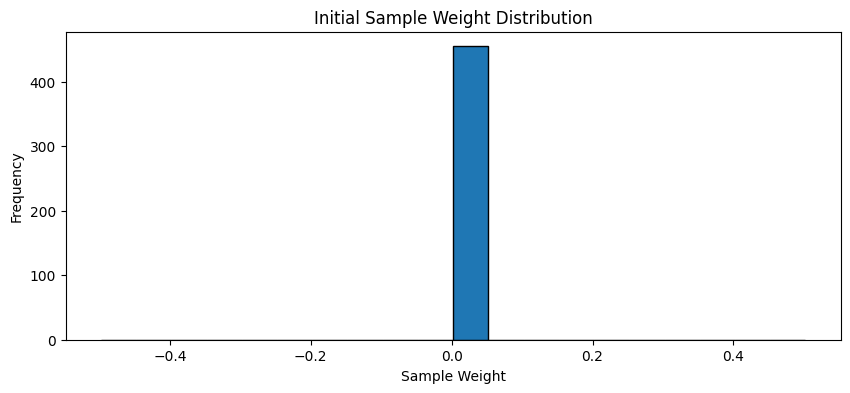

In [8]:
plt.figure(figsize=(10, 4))

plt.hist(sample_weights, bins=20, edgecolor='black')

plt.title("Initial Sample Weight Distribution")
plt.xlabel("Sample Weight")
plt.ylabel("Frequency")

plt.show()

In [9]:
from sklearn.tree import DecisionTreeClassifier

# Create Decision Stump
dt = DecisionTreeClassifier(max_depth=1, random_state=42)

# Train using sample weights
dt.fit(X_train, y_train, sample_weight=sample_weights)

# Predictions on training data
y_pred = dt.predict(X_train)

# Display predictions
print("Actual Labels:")
print(y_train.values[:10])

print("\nPredicted Labels:")
print(y_pred[:10])

Actual Labels:
[ 1 -1  1  1  1  1  1  1  1  1]

Predicted Labels:
[ 1 -1  1  1  1  1  1  1  1  1]


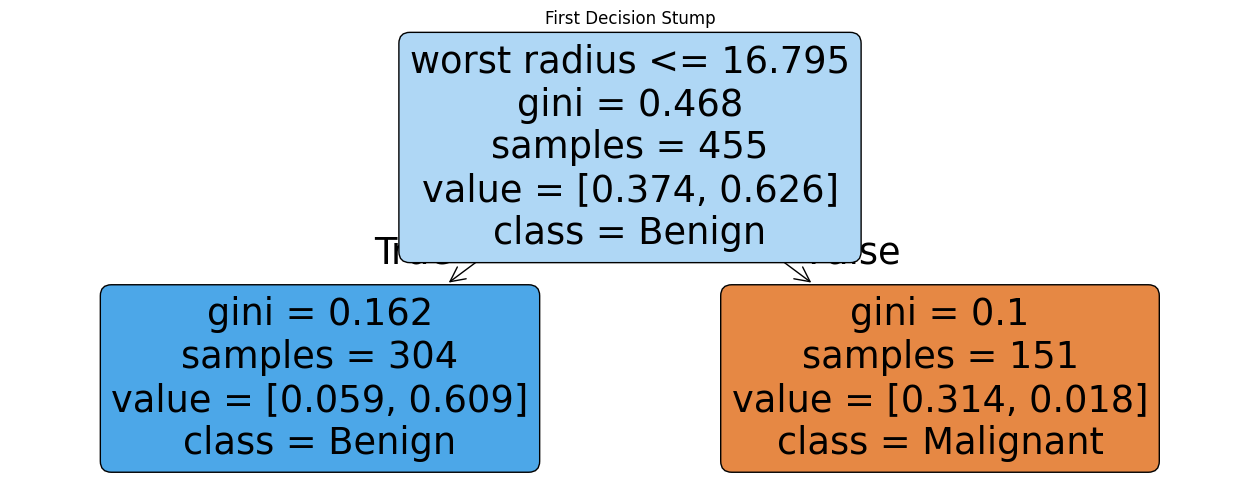

In [10]:
from sklearn.tree import plot_tree

plt.figure(figsize=(16, 6))

plot_tree(
    dt,
    feature_names=X_train.columns,
    class_names=['Malignant', 'Benign'],
    filled=True,
    rounded=True
)

plt.title("First Decision Stump")
plt.show()

In [11]:
# Identify misclassified observations
incorrect = (y_train.values != y_pred)

# Calculate weighted error
error = np.sum(sample_weights * incorrect)

print("Weighted Classification Error:", error)

# Number of misclassified samples
print("Misclassified Samples:", np.sum(incorrect))

# Total training samples
print("Total Samples:", n_samples)

Weighted Classification Error: 0.07692307692307693
Misclassified Samples: 35
Total Samples: 455



## 10. Calculate Alpha – Weak Learner Importance

In AdaBoost, every weak learner receives an importance score called Alpha.

Alpha determines how much influence a weak learner has in the final prediction.

The importance depends on the weighted classification error.

### Formula

Alpha = 1/2 × ln((1 - Error) / Error)

Where:
- Error = Weighted classification error.
- ln = Natural logarithm.
- Alpha = Importance of the weak learner.

### Interpretation

1. Lower error → Higher Alpha → More importance.
2. Higher error → Lower Alpha → Less importance.
3. Error = 0.5 → Alpha = 0 → No contribution.
4. Error greater than 0.5 → Negative Alpha → Weak learner performs worse than random guessing.

A good weak learner should have an error smaller than 0.5.


In [12]:
# Calculate alpha
alpha = 0.5 * np.log((1 - error) / error)

print("Weighted Error:", error)
print("Alpha:", alpha)

Weighted Error: 0.07692307692307693
Alpha: 1.2424533248940002


In [13]:
# Update sample weights
sample_weights = sample_weights * np.exp(
    -alpha * y_train.values * y_pred
)

print("Updated Sample Weights:")
print(sample_weights[:10])

print("\nTotal Weight Before Normalization:", sample_weights.sum())

Updated Sample Weights:
[0.00063445 0.00063445 0.00063445 0.00063445 0.00063445 0.00063445
 0.00063445 0.00063445 0.00063445 0.00063445]

Total Weight Before Normalization: 0.5329387100211931


In [15]:
# Normalize sample weights
sample_weights = sample_weights / sample_weights.sum()

print("Normalized Sample Weights:")
print(sample_weights[:10])

print("\nTotal Weight After Normalization:", sample_weights.sum())

Normalized Sample Weights:
[0.00119048 0.00119048 0.00119048 0.00119048 0.00119048 0.00119048
 0.00119048 0.00119048 0.00119048 0.00119048]

Total Weight After Normalization: 1.0


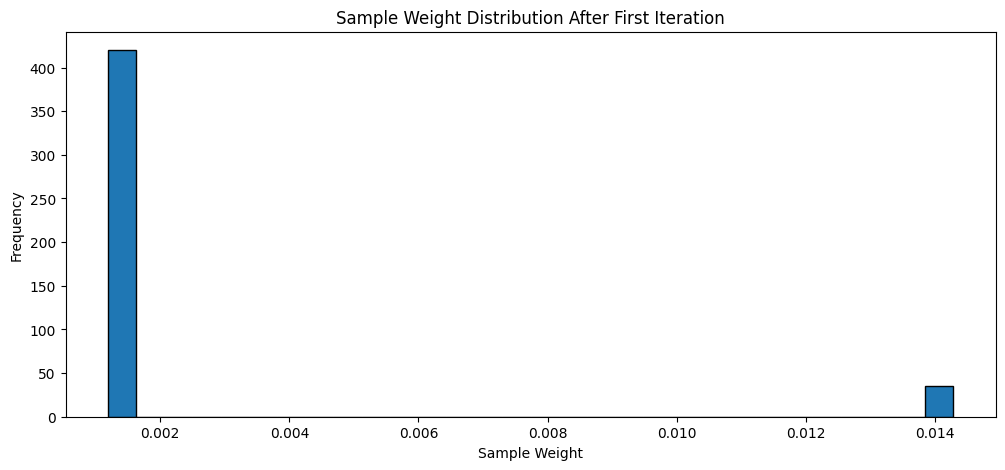

In [18]:
plt.figure(figsize=(12, 5))

plt.hist(
    sample_weights,
    bins=30,
    edgecolor='black'
)

plt.title("Sample Weight Distribution After First Iteration")
plt.xlabel("Sample Weight")
plt.ylabel("Frequency")

plt.show()

In [19]:
# Number of weak learners
n_estimators = 10

# Initialize sample weights
sample_weights = np.ones(len(X_train)) / len(X_train)

# Store weak learners and their alpha values
models = []
alphas = []

# Store iteration details
errors = []

for i in range(n_estimators):

    # 1. Create Decision Stump
    stump = DecisionTreeClassifier(
        max_depth=1,
        random_state=42
    )

    # 2. Train using current sample weights
    stump.fit(
        X_train,
        y_train,
        sample_weight=sample_weights
    )

    # 3. Predict training samples
    y_pred = stump.predict(X_train)

    # 4. Calculate weighted error
    incorrect = (y_train.values != y_pred)

    error = np.sum(sample_weights * incorrect)

    # Stop if the learner is no better than random guessing
    if error >= 0.5:
        break

    # 5. Calculate alpha
    alpha = 0.5 * np.log((1 - error) / error)

    # 6. Update sample weights
    sample_weights *= np.exp(
        -alpha * y_train.values * y_pred
    )

    # 7. Normalize weights
    sample_weights /= sample_weights.sum()

    # 8. Store model and alpha
    models.append(stump)
    alphas.append(alpha)
    errors.append(error)

    print(f"Iteration {i+1}")
    print(f"Weighted Error: {error:.4f}")
    print(f"Alpha: {alpha:.4f}")
    print("-" * 30)

Iteration 1
Weighted Error: 0.0769
Alpha: 1.2425
------------------------------
Iteration 2
Weighted Error: 0.1488
Alpha: 0.8720
------------------------------
Iteration 3
Weighted Error: 0.1410
Alpha: 0.9036
------------------------------
Iteration 4
Weighted Error: 0.2167
Alpha: 0.6425
------------------------------
Iteration 5
Weighted Error: 0.2731
Alpha: 0.4894
------------------------------
Iteration 6
Weighted Error: 0.2050
Alpha: 0.6776
------------------------------
Iteration 7
Weighted Error: 0.2374
Alpha: 0.5835
------------------------------
Iteration 8
Weighted Error: 0.2515
Alpha: 0.5453
------------------------------
Iteration 9
Weighted Error: 0.2706
Alpha: 0.4958
------------------------------
Iteration 10
Weighted Error: 0.2889
Alpha: 0.4505
------------------------------


In [20]:
results = pd.DataFrame({
    'Iteration': range(1, len(models) + 1),
    'Weighted Error': errors,
    'Alpha': alphas
})

results

,Iteration,Weighted Error,Alpha
0,1,0.076923,1.242453
1,2,0.148810,0.871984
2,3,0.140979,0.903591
3,4,0.216709,0.642475
4,5,0.273140,0.489375
5,6,0.205020,0.677606
6,7,0.237411,0.583463
7,8,0.251488,0.545347
8,9,0.270607,0.495772
9,10,0.288861,0.450462


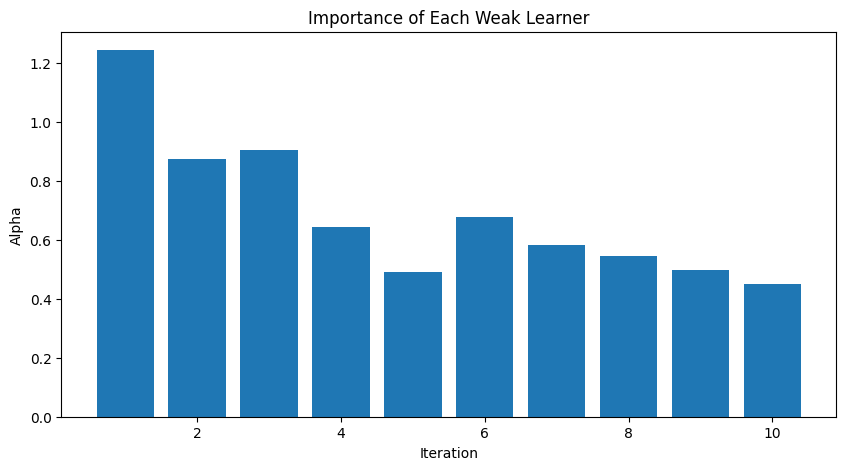

In [21]:
plt.figure(figsize=(10, 5))

plt.bar(results['Iteration'], results['Alpha'])

plt.xlabel("Iteration")
plt.ylabel("Alpha")
plt.title("Importance of Each Weak Learner")

plt.show()

In [25]:
def predict_adaboost(X, models, alphas):

    # Store weighted predictions
    final_predictions = np.zeros(len(X))

    # Iterate through all weak learners
    for model, alpha in zip(models, alphas):

        # Prediction from individual learner
        predictions = model.predict(X)

        # Weighted voting
        final_predictions += alpha * predictions

    # Apply sign function
    return np.sign(final_predictions)

In [26]:
# Predict test data
y_pred_scratch = predict_adaboost(
    X_test,
    models,
    alphas
)

print("Actual Values:")
print(y_test.values[:15])

print("\nPredicted Values:")
print(y_pred_scratch[:15])

Actual Values:
[-1  1 -1  1 -1  1  1 -1 -1 -1  1 -1  1 -1 -1]

Predicted Values:
[-1.  1. -1. -1. -1.  1.  1. -1. -1. -1.  1. -1.  1. -1. -1.]


Scratch AdaBoost Accuracy: 0.9649122807017544


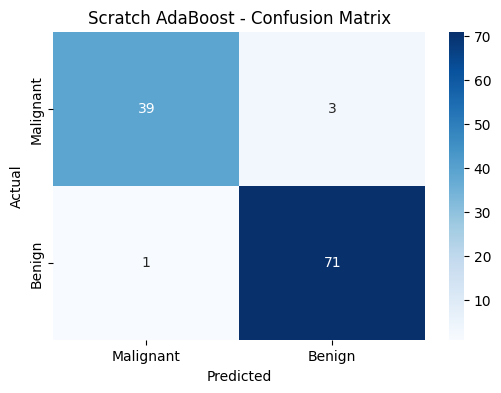

              precision    recall  f1-score   support

   Malignant       0.97      0.93      0.95        42
      Benign       0.96      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



In [27]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Accuracy
accuracy = accuracy_score(y_test, y_pred_scratch)

print("Scratch AdaBoost Accuracy:", accuracy)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_scratch)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Malignant', 'Benign'],
    yticklabels=['Malignant', 'Benign']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Scratch AdaBoost - Confusion Matrix")

plt.show()

# Classification Report
print(classification_report(
    y_test,
    y_pred_scratch,
    target_names=['Malignant', 'Benign']
))


## 21. AdaBoost Using Scikit-learn

Scikit-learn provides AdaBoostClassifier, which implements the AdaBoost algorithm internally.

Instead of manually calculating sample weights, weighted errors, Alpha values and updating weights, the library handles these operations automatically.

We will:

1. Import AdaBoostClassifier.
2. Create a Decision Tree with max_depth=1 as the base estimator.
3. Initialize AdaBoostClassifier with 10 estimators.
4. Train the model.
5. Generate predictions on the test dataset.

We will use the same training and testing datasets used in our scratch implementation.


In [29]:
from sklearn.ensemble import AdaBoostClassifier

# Create base learner
base_model = DecisionTreeClassifier(
    max_depth=1,
    random_state=42
)

# Create AdaBoost classifier
ada_model = AdaBoostClassifier(
    estimator=base_model,
    n_estimators=10,
    learning_rate=1.0,
    random_state=42
)

# Train model
ada_model.fit(X_train, y_train)

# Predictions
y_pred_sklearn = ada_model.predict(X_test)

print("Scikit-learn AdaBoost trained successfully!")

Scikit-learn AdaBoost trained successfully!


In [30]:
# Extract information from sklearn AdaBoost

sklearn_results = pd.DataFrame({
    'Iteration': range(1, len(ada_model.estimators_) + 1),
    'Alpha': ada_model.estimator_weights_,
    'Weighted Error': ada_model.estimator_errors_
})

sklearn_results

,Iteration,Alpha,Weighted Error
0,1,2.484907,0.076923
1,2,1.743969,0.148810
2,3,1.807182,0.140979
3,4,1.284951,0.216709
4,5,0.978749,0.273140
5,6,1.355212,0.205020
6,7,1.166927,0.237411
7,8,1.090694,0.251488
8,9,0.991544,0.270607
9,10,0.900924,0.288861


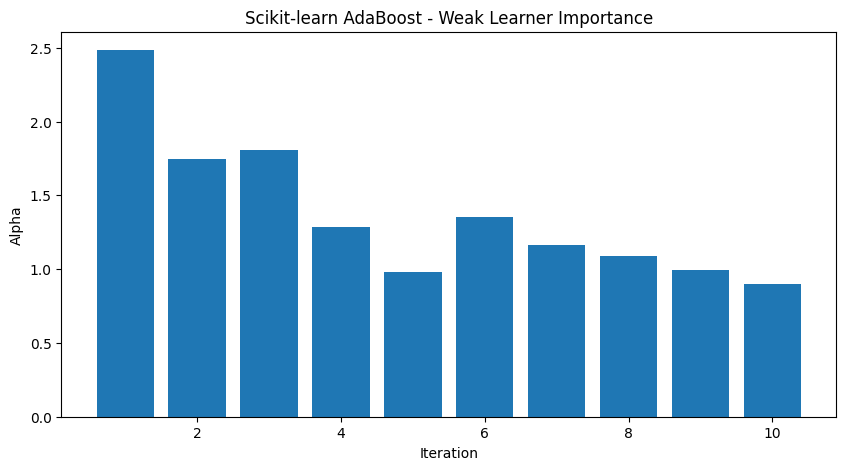

In [31]:
plt.figure(figsize=(10, 5))

plt.bar(
    sklearn_results['Iteration'],
    sklearn_results['Alpha']
)

plt.xlabel("Iteration")
plt.ylabel("Alpha")
plt.title("Scikit-learn AdaBoost - Weak Learner Importance")

plt.show()

Scikit-learn AdaBoost Accuracy: 0.9649122807017544


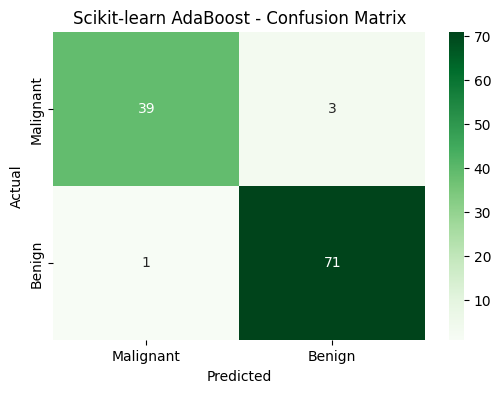

              precision    recall  f1-score   support

   Malignant       0.97      0.93      0.95        42
      Benign       0.96      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



In [32]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Calculate accuracy
sklearn_accuracy = accuracy_score(y_test, y_pred_sklearn)

print("Scikit-learn AdaBoost Accuracy:", sklearn_accuracy)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_sklearn)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Malignant', 'Benign'],
    yticklabels=['Malignant', 'Benign']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Scikit-learn AdaBoost - Confusion Matrix")

plt.show()

# Classification Report
print(classification_report(
    y_test,
    y_pred_sklearn,
    target_names=['Malignant', 'Benign']
))

In [34]:
comparison = pd.DataFrame({
    'Model': ['AdaBoost From Scratch', 'AdaBoost Scikit-learn'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_scratch),
        accuracy_score(y_test, y_pred_sklearn)
    ]
})

comparison

,Model,Accuracy
0,AdaBoost From Scratch,0.964912
1,AdaBoost Scikit-learn,0.964912


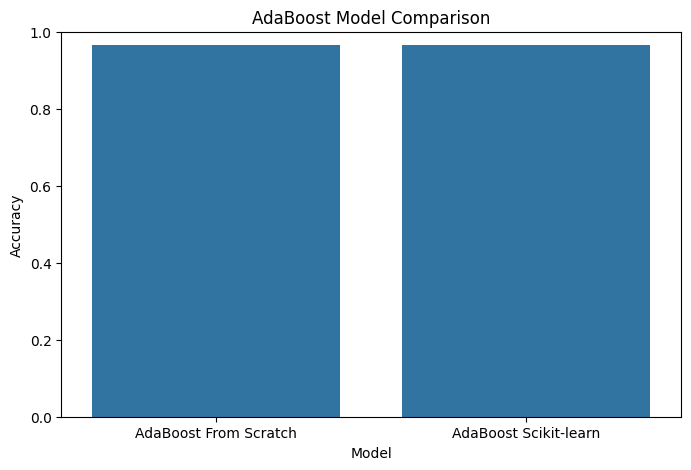

In [35]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=comparison,
    x='Model',
    y='Accuracy'
)

plt.title("AdaBoost Model Comparison")
plt.ylabel("Accuracy")
plt.ylim(0, 1)

plt.show()